# Autoencoder w rozpoznawaniu obrazów

**Autor:** Jakub Psarski <br />
**Data:** 18.11.2026

Program uczy autoenkoder odtwarzać obrazy emotikon o rozmiarze 16x16. Na wejściu i na wyjściu sieci podawany jest ten sam obraz, a funkcją kosztu jest błąd średniokwadratowy (MSE). Enkoder kompresuje obraz do krótkiego wektora cech, który następnie jest wizualizowany metodą t-SNE i wykorzystany do wyszukiwania emotikon algorytmem k-NN.

## Importy i parametry

In [1]:
import cv2
import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers, models
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier

keras.utils.set_random_seed(3721)
SIZE = 16
N_PER_CLASS = 1000
N_QUERIES = 200
LATENT_DIM = 32
EPOCHS = 100
K = 5

## Baza emotikon i zapytania

In [2]:
def make_emoji(c):
    img = np.zeros((64, 64), np.uint8)
    cv2.circle(img, (32, 32), 24, 255, -1)
    cv2.circle(img, (24, 24), 4, 0, -1)
    cv2.circle(img, (40, 24), 4, 0, -1)
    if c == 0:
        cv2.ellipse(img, (32, 36), (13, 10), 0, 0, 180, 0, -1)
    elif c == 1:
        cv2.ellipse(img, (32, 48), (12, 7), 0, 180, 360, 0, 4)
    elif c == 2:
        cv2.rectangle(img, (21, 40), (43, 44), 0, -1)
    else:
        cv2.circle(img, (32, 42), 7, 0, -1)
    return img


def transform(img):
    M = cv2.getRotationMatrix2D(
        (32, 32),
        np.random.uniform(-30, 30),
        np.random.uniform(0.7, 1.1)
    )
    M[0, 1] += np.random.uniform(-0.2, 0.2)
    M[:, 2] += np.random.uniform(-5, 5, 2)
    return cv2.warpAffine(img, M, (64, 64), flags=cv2.INTER_NEAREST)


def prepare(img):
    small = cv2.resize(img, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    return small.ravel() / 255.0


names = np.array(["happy", "sad", "neutral", "surprised"])
db_labels = np.repeat(np.arange(4), N_PER_CLASS)
db_imgs = np.array([prepare(transform(make_emoji(c))) for c in db_labels])
q_labels = np.random.randint(4, size=N_QUERIES)
q_imgs = np.array([prepare(transform(make_emoji(c))) for c in q_labels])
print("database size:", db_imgs.shape)
print("queries:", q_imgs.shape)

database size: (4000, 256)
queries: (200, 256)


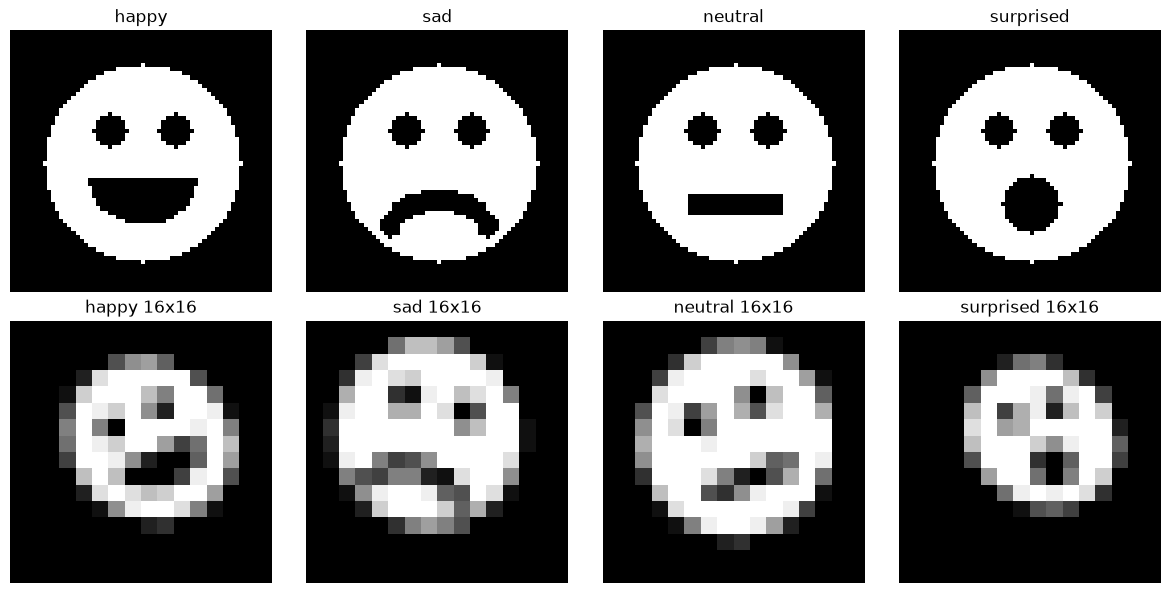

In [3]:
plt.figure(figsize=(12, 6))
for c in range(4):
    plt.subplot(2, 4, c + 1)
    plt.imshow(make_emoji(c), cmap="gray")
    plt.title(names[c])
    plt.axis("off")
    plt.subplot(2, 4, c + 5)
    plt.imshow(db_imgs[c * N_PER_CLASS].reshape(SIZE, SIZE), cmap="gray")
    plt.title(f"{names[c]} {SIZE}x{SIZE}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Autoenkoder

In [4]:
encoder = models.Sequential([
    layers.Input((SIZE * SIZE,)),
    layers.Dense(LATENT_DIM, activation="relu"),
])
decoder = models.Sequential([
    layers.Input((LATENT_DIM,)),
    layers.Dense(SIZE * SIZE, activation="sigmoid"),
])
autoencoder = models.Sequential([encoder, decoder])
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 256)            │         8,448 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,672 (65.12 KB)

 Trainable params: 16,672 (65.12 KB)

 Non-trainable params: 0 (0.00 B)

## Trening

train MSE: 0.0050
test MSE: 0.0052


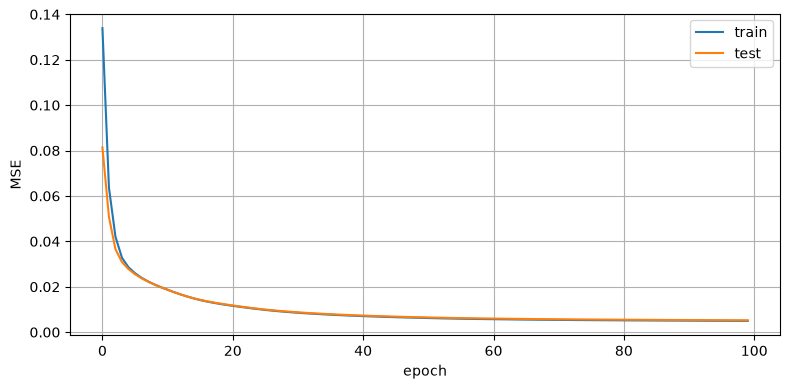

In [5]:
history = autoencoder.fit(
    db_imgs, db_imgs,
    epochs=EPOCHS,
    batch_size=64,
    shuffle=True,
    validation_data=(q_imgs, q_imgs),
    verbose=0
)
print(f"train MSE: {history.history['loss'][-1]:.4f}")
print(f"test MSE: {history.history['val_loss'][-1]:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="test")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

## Rekonstrukcja obrazów

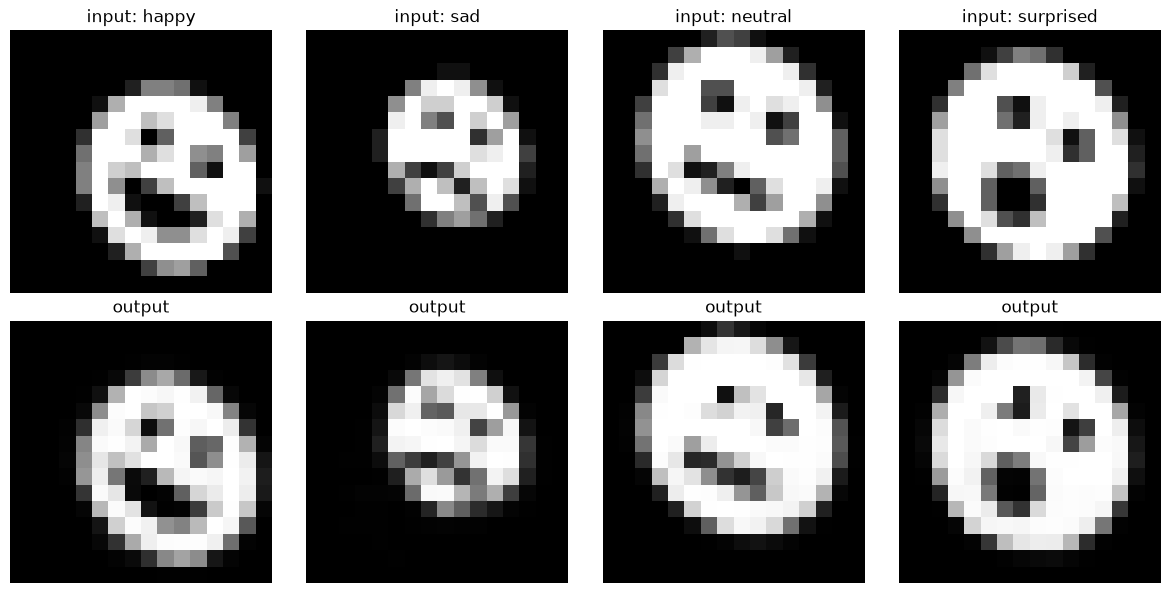

In [6]:
examples = [np.where(q_labels == c)[0][0] for c in range(4)]
reconstructed = autoencoder.predict(q_imgs[examples], verbose=0)

plt.figure(figsize=(12, 6))
for i, q in enumerate(examples):
    plt.subplot(2, 4, i + 1)
    plt.imshow(q_imgs[q].reshape(SIZE, SIZE), cmap="gray")
    plt.title("input: " + names[q_labels[q]])
    plt.axis("off")
    plt.subplot(2, 4, i + 5)
    plt.imshow(reconstructed[i].reshape(SIZE, SIZE), cmap="gray")
    plt.title("output")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Wizualizacja cech t-SNE

encoder features: (4000, 32)


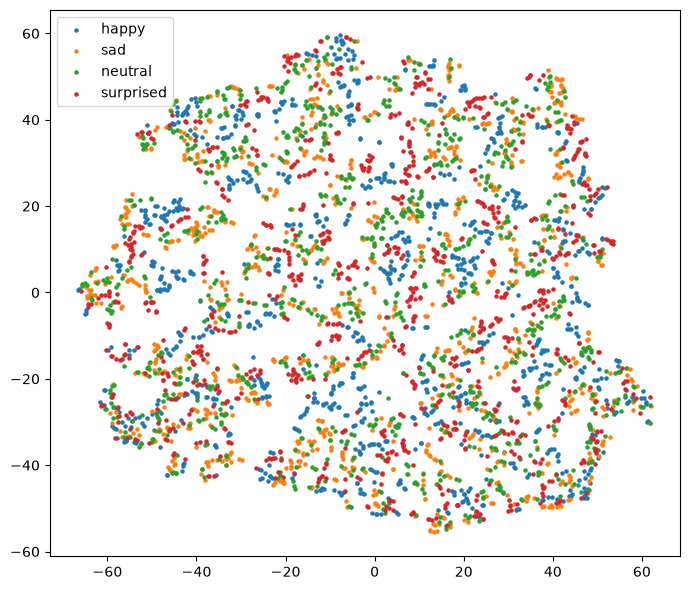

In [7]:
D = encoder.predict(db_imgs, verbose=0)
Q = encoder.predict(q_imgs, verbose=0)
print("encoder features:", D.shape)

E = TSNE(n_components=2, random_state=0).fit_transform(D)

plt.figure(figsize=(7, 6))
for c in range(4):
    plt.scatter(E[db_labels == c, 0], E[db_labels == c, 1], s=5, label=names[c])
plt.legend()
plt.tight_layout()
plt.show()

## Wyszukiwanie k-NN

In [8]:
def knn_accuracy(D, Q, k):
    knn = KNeighborsClassifier(n_neighbors=k).fit(D, db_labels)
    return np.mean(knn.predict(Q) == q_labels) * 100


print(f"pixels {SIZE}x{SIZE}, k={K}: {knn_accuracy(db_imgs, q_imgs, K):.1f}%")
print(f"autoencoder features, k={K}: {knn_accuracy(D, Q, K):.1f}%")

pixels 16x16, k=5: 79.5%
autoencoder features, k=5: 80.0%


## Przykładowe wyniki wyszukiwania

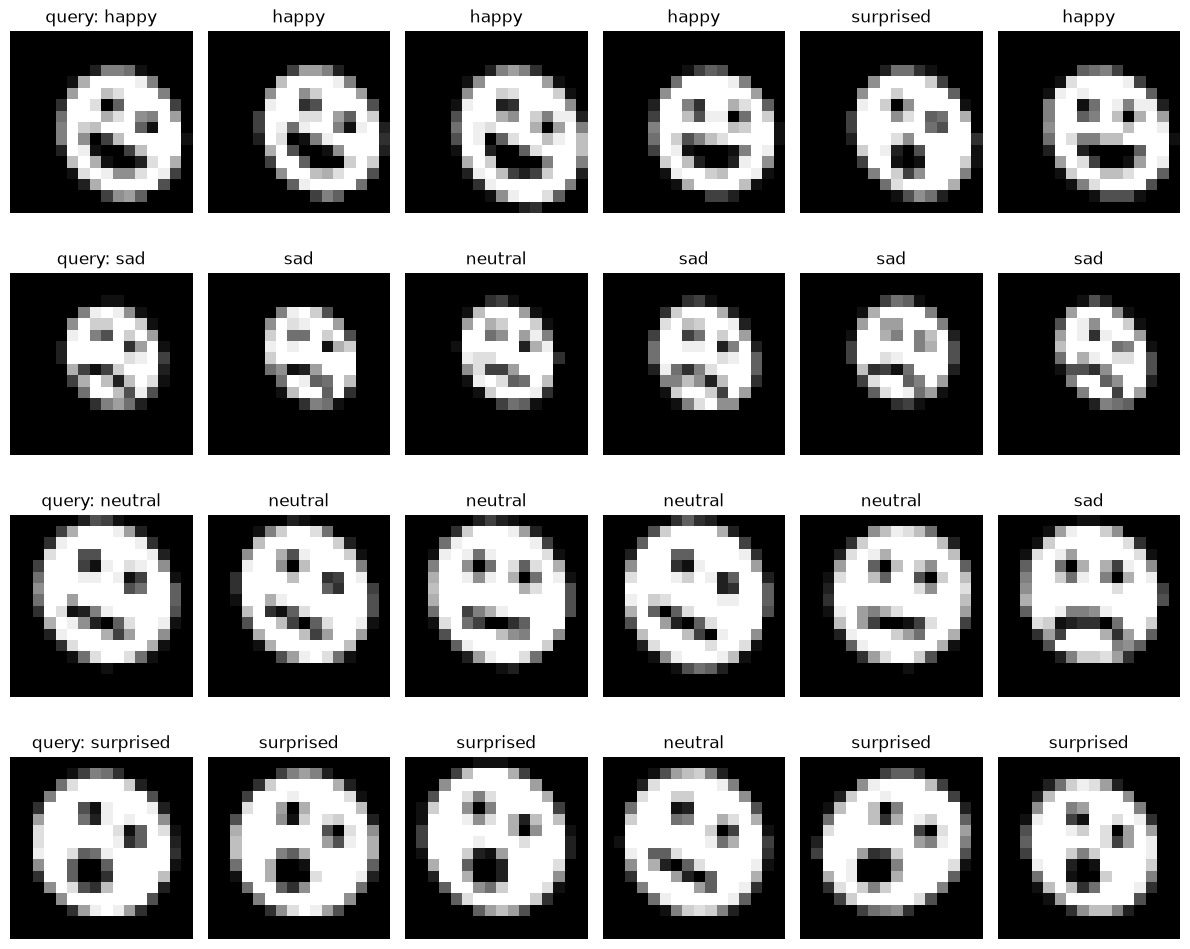

In [9]:
knn = KNeighborsClassifier(n_neighbors=K).fit(D, db_labels)
examples = [np.where(q_labels == c)[0][0] for c in range(4)]

plt.figure(figsize=(12, 10))
for r, q in enumerate(examples):
    _, idx = knn.kneighbors(Q[q:q + 1], n_neighbors=K)
    plt.subplot(4, K + 1, (K + 1) * r + 1)
    plt.imshow(q_imgs[q].reshape(SIZE, SIZE), cmap="gray")
    plt.title("query: " + names[q_labels[q]])
    plt.axis("off")
    for j, found in enumerate(idx[0]):
        plt.subplot(4, K + 1, (K + 1) * r + j + 2)
        plt.imshow(db_imgs[found].reshape(SIZE, SIZE), cmap="gray")
        plt.title(names[db_labels[found]])
        plt.axis("off")
plt.tight_layout()
plt.show()

## Wnioski

Autoenkoder z jedną warstwą ukrytą (256 -> 32 -> 256) dobrze nauczył się odtwarzać emotikony 16x16 – błąd MSE wynosi ok. 0,005 zarówno dla bazy, jak i dla zapytań, których sieć nie widziała podczas treningu, więc sieć nie przeuczyła się. Enkoder kompresuje obraz 8 razy (z 256 do 32 liczb), a zrekonstruowane obrazy zachowują kształt twarzy, oczy i usta. Na wykresie t-SNE klasy nie tworzą osobnych skupisk, widać jedynie małe lokalne grupki punktów tej samej klasy. Wynika to z tego, że autoenkoder uczy się odtwarzać cały obraz, a największe różnice między obrazami wynikają z przesunięcia, obrotu i skali, a nie z kształtu ust, który zajmuje tylko kilka pikseli. Mimo to cechy z enkodera dają w k-NN skuteczność podobną do samych pikseli (80% wobec 79,5%), a przy tym wektor cech jest 8 razy krótszy (32 zamiast 256 liczb), więc enkoder zachowuje informację potrzebną do rozpoznania emotikony przy dużo mniejszym wymiarze.